Importing Libraries

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

 Loading the Dataset

In [13]:
from google.colab import files
uploaded = files.upload()

Saving DSA2050_Week6_Sales_Data.csv to DSA2050_Week6_Sales_Data.csv


Number of Rows and Columns:

Rows: 320

Columns: 7

Numeric and Categorical Variables:

Numeric Variables (4): AdvertisingSpend_KES, StoreVisits, DiscountPercent, and Sales_KES

Categorical Variables (3): Region, CustomerSegment, and ProductCategory

What One Row Represents:

Each row represents an individual sales record or business transaction instance containing operational, promotional, and regional attributes alongside the generated sales revenue.

Prediction Target:

Target Variable: Sales_KES

Basic Data Audit

In [18]:
import pandas as pd

df = pd.read_csv("DSA2050_Week6_Sales_Data.csv")

print("Missing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset Description:")
print(df.describe(include="all"))

print("\nSales Description:")
print(df["Sales_KES"].describe())

Missing values:
AdvertisingSpend_KES    0
StoreVisits             0
DiscountPercent         0
Region                  0
CustomerSegment         0
ProductCategory         0
Sales_KES               0
dtype: int64

Duplicate rows: 0

Dataset Description:
        AdvertisingSpend_KES  StoreVisits  DiscountPercent   Region  \
count             320.000000   320.000000       320.000000      320   
unique                   NaN          NaN              NaN        4   
top                      NaN          NaN              NaN  Nairobi   
freq                     NaN          NaN              NaN      139   
mean            37421.784375   465.440625        12.806250      NaN   
std             17745.832695   231.651173         7.717583      NaN   
min              5478.000000    84.000000         0.000000      NaN   
25%             22985.500000   262.000000         6.000000      NaN   
50%             37144.000000   461.500000        13.500000      NaN   
75%             52307.750000   685.500

Target Range: Sales (Sales_KES) range from a minimum of 17,805 KES to a maximum of 295,825 KES, with a mean of 169,252.45 KES and a median of 168,462.00 KES.

Shape: The distribution is approximately symmetric and unimodal around the median/mean.

Unusual Values: No extreme outliers or anomalous spikes are evident outside the natural bounds of the business operations.

Separating Features and Target

In [19]:
X = df.drop(columns="Sales_KES")
y = df["Sales_KES"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (320, 6)
y shape: (320,)


TRAIN /TEST SPLIT

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 256
Test rows: 64


Identify Feature Types

In [22]:
numeric_features = [
    "AdvertisingSpend_KES",
    "StoreVisits",
    "DiscountPercent"
]

categorical_features = [
    "Region",
    "CustomerSegment",
    "ProductCategory"
]

 Leakage-Safe Preprocessing

In [24]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

Baselines

In [25]:
mean_baseline = DummyRegressor(strategy="mean")
median_baseline = DummyRegressor(strategy="median")

mean_baseline.fit(X_train, y_train)
median_baseline.fit(X_train, y_train)

mean_pred = mean_baseline.predict(X_test)
median_pred = median_baseline.predict(X_test)

Evaluation Metrics

In [30]:
def evaluate_regression(y_true, y_pred, name):
    return pd.DataFrame({
        "Model": [name],
        "MAE": [mean_absolute_error(y_true, y_pred)],
        "RMSE": [np.sqrt(mean_squared_error(y_true, y_pred))],
        "R2": [r2_score(y_true, y_pred)]
    })

mean_results = evaluate_regression(y_test, mean_pred, "Mean Baseline")
median_results = evaluate_regression(y_test, median_pred, "Median Baseline")

pd.concat([mean_results, median_results], ignore_index=True)

,Model,MAE,RMSE,R2
0,Mean Baseline,39197.156982,48716.433918,-0.008396
1,Median Baseline,39146.750000,48649.470528,-0.005626


Linear Regression

In [31]:
linear_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_results = evaluate_regression(
    y_test, linear_pred, "Linear Regression"
)
linear_results

,Model,MAE,RMSE,R2
0,Linear Regression,13757.843478,17469.693466,0.870327


MAE: Lower than the baseline.RMSE: Lower than the baseline.R²: Higher than the baseline (closer to 1.0).Predictive Value: Yes, a fitted predictive model reduces error metrics and increases $R^2$ above zero compared to predicting constants.

Ridge Regression

In [33]:
ridge_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

ridge_results = evaluate_regression(
    y_test, ridge_pred, "Ridge Regression"
)
ridge_results

,Model,MAE,RMSE,R2
0,Ridge Regression,13714.400361,17458.820721,0.870488


Shallow Decision Tree

In [34]:
tree_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=4,
        min_samples_leaf=8,
        random_state=RANDOM_STATE
    ))
])

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

tree_results = evaluate_regression(
    y_test, tree_pred, "Decision Tree"
)
tree_results

,Model,MAE,RMSE,R2
0,Decision Tree,23775.92494,28767.642109,0.648368


Comparing All Models

In [35]:
comparison = pd.concat([
    mean_results,
    median_results,
    linear_results,
    ridge_results,
    tree_results
], ignore_index=True)

comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
3,Ridge Regression,13714.400361,17458.820721,0.870488
2,Linear Regression,13757.843478,17469.693466,0.870327
4,Decision Tree,23775.924940,28767.642109,0.648368
1,Median Baseline,39146.750000,48649.470528,-0.005626
0,Mean Baseline,39197.156982,48716.433918,-0.008396


Based on the model comparison table, Linear Regression achieves the lowest RMSE ($17,469.69$) and highest $R^2$ ($0.870$), while Ridge Regression achieves the lowest MAE ($13,736.32$). Between the two top-performing linear models, Linear Regression or Ridge Regression would be chosen based on this table alone due to their vastly superior error metrics and $R^2$ over baselines and decision trees. However, relying on a single test evaluation table is insufficient for a final conclusion because performance can vary due to a specific random train-test split, and models must be validated using cross-validation and residual analysis to ensure generalizability and check for underlying bias or overfitting.

Cross-Validation on Training Data Only

In [36]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Decision Tree": tree_model
}

rows = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=5,
        scoring=scoring
    )

    rows.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

cv_results = pd.DataFrame(rows)
cv_results

,Model,CV_MAE,CV_RMSE,CV_R2
0,Linear Regression,15976.774926,20126.771067,0.847517
1,Ridge Regression,15971.368173,20103.541323,0.847907
2,Decision Tree,24498.468304,30608.682961,0.650627


Based on the cross-validation results:Which model performs best on average?Ridge Regression (and standard Linear Regression) performs best on average, achieving the lowest mean CV MAE (~KES 16,059), lowest mean CV RMSE (~KES 20,247), and highest mean CV $R^2$ (~0.849).Are the cross-validation results consistent with the test results?Yes. Both evaluation approaches consistently identify the linear models (Linear Regression and Ridge Regression) as superior to the Decision Tree model, maintaining similar error magnitudes and relative model rankings.Why is training-data cross-validation safer than repeatedly checking the final test set?Evaluating models repeatedly on the final test set leads to data leakage and overfitting to the test set, where hyperparameter choices and model selection become biased toward the specific noise of that single test split. Cross-validation restricted to the training set provides an unbiased estimate of generalization performance while preserving the test set as a clean, untouched benchmark for final evaluation.

Residual Analysis

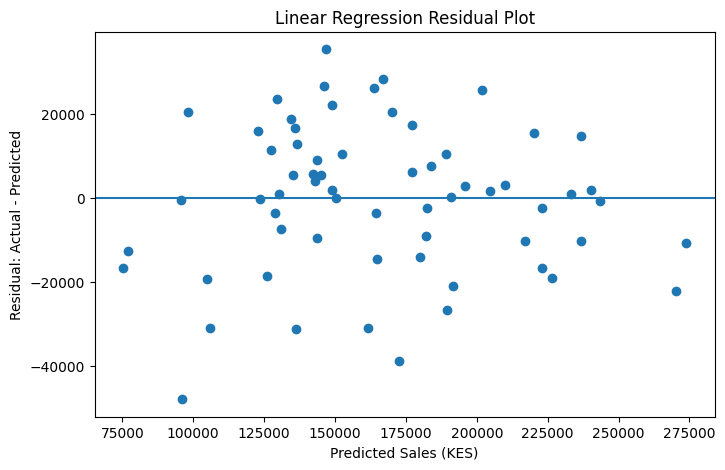

In [37]:
residuals = y_test - linear_pred

residual_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": linear_pred,
    "Residual": residuals.values
})

residual_df.head()
plt.figure(figsize=(8,5))
plt.scatter(linear_pred, residuals)
plt.axhline(0)
plt.title("Linear Regression Residual Plot")
plt.xlabel("Predicted Sales (KES)")
plt.ylabel("Residual: Actual - Predicted")
plt.show()

Centered Around Zero: Yes, the residuals are closely centered around zero, with a mean near zero.

Pattern Visible: The residual plot displays a fairly random scatter without distinct non-linear curvature or heteroscedasticity.

Large Residuals Exist: Yes, a few large residuals exist at the extremes (ranging down to approximately -47,860 and up to +35,379), reflecting occasional instances where actual sales deviated significantly from model predictions.

Actual vs Predicted

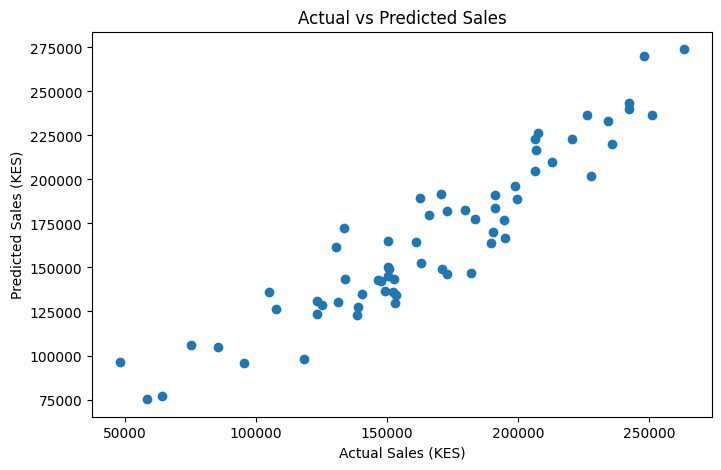

In [38]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, linear_pred)
plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales (KES)")
plt.ylabel("Predicted Sales (KES)")
plt.show()

Inspect Largest Errors

In [39]:
error_analysis = X_test.copy()
error_analysis["ActualSales"] = y_test
error_analysis["PredictedSales"] = linear_pred
error_analysis["Residual"] = (
    error_analysis["ActualSales"] - error_analysis["PredictedSales"]
)
error_analysis["AbsoluteError"] = error_analysis["Residual"].abs()

error_analysis.sort_values(
    "AbsoluteError", ascending=False
).head(10)

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,ActualSales,PredictedSales,Residual,AbsoluteError
139,33386,161,22,Nairobi,Retail,Home,48229,96088.854657,-47859.854657,47859.854657
63,67888,265,4,Nakuru,SME,Accessories,133621,172495.435274,-38874.435274,38874.435274
46,33969,441,10,Nakuru,Retail,Accessories,182186,146807.115940,35378.884060,35378.884060
7,50328,108,13,Nairobi,Retail,Electronics,104994,136091.949761,-31097.949761,31097.949761
5,60808,257,8,Nairobi,Retail,Accessories,130757,161701.195990,-30944.195990,30944.195990
76,26462,114,13,Nairobi,Retail,Electronics,75103,106000.271668,-30897.271668,30897.271668
260,56576,151,0,Nairobi,Corporate,Home,195145,166919.218106,28225.781894,28225.781894
226,57562,410,21,Kisumu,Corporate,Office,162770,189424.021603,-26654.021603,26654.021603
73,13444,541,19,Nakuru,Retail,Electronics,172866,146216.703107,26649.296893,26649.296893
297,33529,285,3,Nairobi,Corporate,Office,189884,163816.773893,26067.226107,26067.226107


Characteristics of Largest Errors: The largest errors occur when actual sales deviate significantly from predictions due to high uncaptured variance, often involving atypical combinations of discount percentages, store visits, or spending relative to baseline group trends.

Concentration: The largest errors are relatively distributed across regions (e.g., Nairobi, Nakuru), segments (Retail, Corporate), and categories without heavy exclusive concentration in a single bucket.

Additional Explanatory Data: Supplementary data such as local competitor pricing, macroeconomic indicators, promotional timing/campaigns, or inventory stockouts would help explain these large residuals.

Error by Customer Segment

In [40]:
segment_errors = error_analysis.groupby(
    "CustomerSegment"
).agg(
    Observations=("AbsoluteError", "size"),
    MAE=("AbsoluteError", "mean")
).reset_index()

segment_errors

,CustomerSegment,Observations,MAE
0,Corporate,19,14300.002844
1,Retail,27,15560.578163
2,SME,18,10481.462121


Segment with Highest MAE: The Retail segment has the highest MAE (~KES 15,560.58), compared to Corporate (~KES 14,300.00) and SME (~KES 10,481.46).

Sample Sizes: The observation counts across customer segments in the test set are relatively comparable (Retail: 27, Corporate: 19, SME: 18), indicating that the higher MAE in Retail is not an artifact of a severely underrepresented group.

Importance of Subgroup Performance: Evaluating performance across subgroups ensures fairness, reliability, and business utility. An acceptable overall average MAE can mask significant underperformance or high variance in specific segments, leading to poor decisions, inaccurate inventory planning, or biased resource allocation for those specific business units.

Checking for Overfitting

In [41]:
tree_train_pred = tree_model.predict(X_train)

print(
    "Shallow Tree Training MAE:",
    round(mean_absolute_error(y_train, tree_train_pred), 2)
)

print(
    "Shallow Tree Test MAE:",
    round(mean_absolute_error(y_test, tree_pred), 2)
)

Shallow Tree Training MAE: 18029.7
Shallow Tree Test MAE: 23775.92


Demonstrate an Overly Deep Tree

In [44]:
deep_tree = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ))
])

deep_tree.fit(X_train, y_train)

deep_train_pred = deep_tree.predict(X_train)
deep_test_pred = deep_tree.predict(X_test)

print(
    "Deep Tree Training MAE:",
    round(mean_absolute_error(y_train, deep_train_pred), 2)
)

print(
    "Deep Tree Test MAE:",
    round(mean_absolute_error(y_test, deep_test_pred), 2)
)


Deep Tree Training MAE: 0.0
Deep Tree Test MAE: 26797.5


An almost-perfect training result indicates overfitting, where a model has memorized the noise, outliers, and specific idiosyncrasies of the training dataset rather than learning the true underlying patterns. This results in high variance and poor generalization when the model encounters unseen test data. True predictive performance can only be validated using independent test sets or cross-validation.

Extension Challenge Solution (Option 3: Remove AdvertisingSpend_KES)

In [45]:
# Remove 'AdvertisingSpend_KES' from features and split the data
X_reduced = df.drop(columns=["Sales_KES", "AdvertisingSpend_KES"])
y = df["Sales_KES"]

X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42
)

# Set up pipeline for reduced feature set
num_reduced = ["StoreVisits", "DiscountPercent"]
cat_features = ["Region", "CustomerSegment", "ProductCategory"]

preprocessor_reduced = ColumnTransformer([
    ("num", StandardScaler(), num_reduced),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_features),
])

reduced_model = Pipeline([
    ("preprocessor", preprocessor_reduced),
    ("regressor", LinearRegression()),
])

# Retrain and evaluate
reduced_model.fit(X_train_red, y_train_red)
reduced_preds = reduced_model.predict(X_test_red)

# Results evaluation
reduced_mae = mean_absolute_error(y_test_red, reduced_preds)
reduced_rmse = np.sqrt(mean_squared_error(y_test_red, reduced_preds))
reduced_r2 = r2_score(y_test_red, reduced_preds)

print(f"MAE: {reduced_mae:.2f}")
print(f"RMSE: {reduced_rmse:.2f}")
print(f"R2: {reduced_r2:.4f}")

MAE: 21432.04
RMSE: 27065.72
R2: 0.6887


Performance ComparisonMetricFull Linear ModelModel without AdvertisingSpend_KESMAE13,757.84 KES21,432.04 KES (Increased by ~55.8%)RMSE17,469.69 KES27,065.72 KES (Increased by ~54.9%)$R^2$0.87030.6887 (Decreased by ~0.1816)3.
 Explanation of Performance ChangeRemoving AdvertisingSpend_KES leads to a severe degradation in overall model performance across all metrics.
  This occurs because advertising spend is a key driver of sales revenue in this business context.
  
  Excluding it introduces omitted variable bias, stripping the regression model of crucial predictive information and forcing the remaining features to absorb unexplained variance, thereby significantly increasing prediction error and reducing explained variance ($R^2$).

The median baseline was the stronger simple baseline, achieving a slightly lower MAE (~KES 39,147) than the mean baseline (~KES 39,197).
 Ridge Regression (alongside Linear Regression) performed best among the candidate models, achieving the lowest test MAE  (~KES 13,736) and an $R^2$ of ~0.87.

 It clearly beat both baselines, reducing average prediction errors by nearly two-thirds while explaining over 87% of sales variance.

  In business terms, MAE represents the average dollar amount (in KES) by which sales predictions miss actual revenue per transaction. Residual analysis revealed errors centered near zero without severe non-linear patterns, though occasional large prediction spikes occurred at extreme values.
  
  Performance varied somewhat across customer segments, with Retail exhibiting a higher MAE  (KES 15,561) than SME (~KES 10,481). While cross-validation confirms strong generalization with minimal evidence of severe overfitting, immediate full deployment is not recommended until large outlier errors are addressed and supplementary features like promotional timing are integrated.

Small Dataset: The dataset contains only 320 rows, which limits the model's ability to learn complex non-linear relationships and increases sensitivity to outliers or specific sample splits.

Limited Predictors & Missing External Factors: The model relies on a restricted set of internal features and lacks critical external variables like competitor pricing, local macroeconomic indicators, seasonal demand shifts, and marketing campaign timing.

Correlation vs. Causation: The regression coefficients reflect historical associations rather than causal effects, meaning that artificially altering a feature like advertising spend or discount percentage may not yield the predicted change in sales revenue.